# UCS420: Cognitive Computing
## Lab Assignment 10: Healthcare Cognitive Assistant

---
### **Student Information**
- **Student Name:** Bisman Singh Rai
- **Roll Number:** 1024160130
- **Batch:** 3p11
- **Course:** UCS420 - Cognitive Computing



---
### **Assignment Objectives & Logical Architecture**
This notebook implements an end-to-end Python-based Healthcare Cognitive Assistant for cardiovascular health. The assistant integrates the 8 logical development steps established in `Lab-10.pptx`:
1. **Labelled Corpus Development:** $\ge 40$ queries across $\ge 5$ intent categories (72 queries across 6 intents).
2. **Hierarchical Taxonomy:** $\ge 4$ major cardiac categories with $\ge 2$ subcategories each.
3. **Domain Ontology:** $\ge 8$ cardiac concepts and $\ge 10$ semantic relationships.
4. **NLP Preprocessing Pipeline:** Lowercasing, tokenization, stopword removal, and lemmatization.
5. **Machine Learning Classifier:** TF-IDF feature extraction with Multinomial Naive Bayes & Logistic Regression.
6. **Model Evaluation:** Accuracy, Precision, Recall, F1-score, and Confusion Matrix visualization.
7. **Clinical Knowledge Base:** Comprehensive domain guidance for each intent category.
8. **Cognitive Decision Rules:** Implementation of 6 rules including emergency escalation, low-confidence handling, and unsupported query detection.
9. **Single Integrated Assistant:** Fusing NLP, intent classification, reasoning, and knowledge retrieval.
10. **Deployment & Testing:** Interactive interface with mandatory verification against 5 key test scenarios.

In [1]:
# Step 0: Environment Setup & Dependency Imports
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Natural Language Toolkit (NLTK) imports
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Scikit-learn imports for ML and Evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Download required NLTK corpora safely
for resource in ['punkt', 'stopwords', 'wordnet', 'omw-1.4', 'punkt_tab']:
    try:
        nltk.download(resource, quiet=True)
    except Exception as error_message:
        print(f"Notice during {resource} verification: {error_message}")

print("All dependencies imported successfully!")
print(f"Student: Bisman Singh Rai | Roll Number: 1024160130 | Batch: 3p11")
print(f"Assigned Role: Heart Health Information Assistant")

All dependencies imported successfully!
Student: Bisman Singh Rai | Roll Number: 1024160130 | Batch: 3p11
Assigned Role: Heart Health Information Assistant


---
## Requirement 1: Labelled Corpus Development
- **Goal:** Develop a labelled corpus containing at least 40 queries across 5 or more intent categories.
- **Implementation:** We create a rich dataset containing **72 authentic user queries** systematically distributed across **6 core cardiovascular intent categories** (12 queries per intent):
  1. `heart_attack_symptoms`: Early warning signs, acute chest pain, radiating distress, and myocardial infarction indicators.
  2. `blood_pressure_hypertension`: Normal BP values, hypertension causes, systolic/diastolic readings, and BP spikes.
  3. `diet_heart_nutrition`: Mediterranean diet, low-sodium intake, cholesterol reduction, cooking oils, and arterial plaque prevention.
  4. `exercise_lifestyle_cardio`: Safe aerobic routines, brisk walking, target heart rates, smoking cessation, and stress relief.
  5. `medications_heart_drugs`: Statins, baby aspirin, beta-blockers, ACE inhibitors, side effects, and missed doses.
  6. `preventive_screening_tests`: ECG/EKG scans, lipid profile blood tests, echocardiograms, stress tests, and cardiac calcium CT.

In [2]:
# Requirement 1: Create Labelled Corpus for Heart Health Assistant
# Human-readable dictionary mapping intent categories to sample patient queries

cardiac_queries_corpus = {
    'heart_attack_symptoms': [
        'What are the common symptoms of a heart attack?',
        'What warning signs indicate someone is having a heart attack?',
        'I have severe chest pain and arm numbness, is it a heart attack symptom?',
        'Can jaw pain and shortness of breath be symptoms of a heart attack?',
        'What does heart attack chest pain and tightness feel like?',
        'Are heart attack symptoms different in women than men?',
        'Sudden chest pressure, sweating, and nausea - are these heart attack signs?',
        'How to recognize the early warning symptoms of cardiac arrest and heart attack?',
        'Is radiating pain in left shoulder a symptom of heart attack?',
        'What symptoms warn of an upcoming heart attack or myocardial infarction?',
        'How do I identify acute chest pain symptoms of a heart attack?',
        'What are typical signs and symptoms when experiencing a heart attack?'
    ],
    'blood_pressure_hypertension': [
        'What is a normal blood pressure reading for adults?',
        'My blood pressure reading is 145/90 mmHg, do I have high blood pressure?',
        'How does chronic high blood pressure cause hypertension and heart damage?',
        'What can I do to lower my high blood pressure naturally?',
        'What symptoms indicate severe high blood pressure or hypertension?',
        'What causes high blood pressure and hypertension spikes?',
        'What is the difference between systolic and diastolic blood pressure readings?',
        'How often should I check my blood pressure reading at home for hypertension?',
        'Does high salt intake increase blood pressure and hypertension risk?',
        'What reading defines a severe blood pressure hypertensive crisis?',
        'How to safely manage high blood pressure and hypertension levels?',
        'Can stress cause sudden spikes in blood pressure readings?'
    ],
    'diet_heart_nutrition': [
        'What is the best heart healthy diet for cardiovascular wellness?',
        'Which foods should I include in a heart healthy diet?',
        'How does eating saturated fat affect cholesterol in a cardiac diet?',
        'Can a Mediterranean diet reduce heart disease risk?',
        'What foods and diet choices help lower bad LDL cholesterol?',
        'Why is low sodium salt diet recommended for heart disease patients?',
        'Which cooking oils are best for a cardiac healthy diet?',
        'Are fish and omega 3 fatty acids good for a heart healthy diet?',
        'What foods should I avoid on a heart disease prevention diet?',
        'How much sodium and salt can I eat per day on a cardiac diet?',
        'Can high fiber foods and oatmeal in my diet protect heart health?',
        'What are the dietary guidelines for healthy heart nutrition?'
    ],
    'exercise_lifestyle_cardio': [
        'What cardio exercises and workouts are safe for heart patients?',
        'How many minutes of aerobic exercise should I do weekly for heart fitness?',
        'Is brisk walking exercise good for strengthening the heart muscle?',
        'What lifestyle habits and physical exercise keep the cardiovascular system fit?',
        'How does regular exercise and physical activity lower heart disease risk?',
        'Can heavy gym weightlifting exercise be dangerous for heart patients?',
        'What target heart rate should I maintain during cardio exercise training?',
        'How does quitting smoking as a lifestyle change improve heart health?',
        'Can daily stress reduction and yoga exercise help heart health?',
        'What is the best safe exercise routine for cardiac rehab patients?',
        'How does sedentary lifestyle without exercise damage heart health?',
        'How much moderate aerobic exercise is recommended for cardiac fitness?'
    ],
    'medications_heart_drugs': [
        'What is the purpose of taking statin medications for cholesterol?',
        'Why do doctors prescribe baby aspirin medication as a blood thinner?',
        'How do beta blocker medications work to control heart rate and pressure?',
        'What are common side effects of heart medications like ACE inhibitors?',
        'What should I do if I miss a dose of my heart medication or pill?',
        'Can I stop taking my prescribed heart medications if I feel better?',
        'How do blood thinner medications prevent blood clots in heart disease?',
        'Are over the counter pain medications safe to take with heart prescription drugs?',
        'Why are diuretic water pills prescribed as heart medications?',
        'How do calcium channel blocker medications help heart patients?',
        'What precautions should I take when taking daily cardiovascular medications?',
        'Can prescription heart medications interact with herbal supplements?'
    ],
    'preventive_screening_tests': [
        'What does an ECG electrocardiogram test show about the heart?',
        'When should I get a lipid panel blood test to screen for heart disease?',
        'How does an echocardiogram ultrasound test evaluate heart function?',
        'What happens during a cardiac treadmill stress test screening?',
        'What does an elevated troponin test mean during heart screening?',
        'How often should adults get preventive cardiac screening and checkup tests?',
        'What is a coronary calcium scan CT test for heart disease screening?',
        'How does a 24 hour Holter monitor test detect heart arrhythmias?',
        'What diagnostic screening tests check for coronary artery blockages?',
        'Why are routine cardiovascular screening tests important for early detection?',
        'What blood tests are performed during a comprehensive heart screening?',
        'Which diagnostic test is best to check heart rhythm and valve function?'
    ]
}

# Transform corpus into a structured Pandas DataFrame
corpus_records = []
for intent_label, query_list in cardiac_queries_corpus.items():
    for single_query in query_list:
        corpus_records.append({
            'patient_query': single_query,
            'intent_category': intent_label
        })

patient_corpus_df = pd.DataFrame(corpus_records)

print(f"Total Labelled Queries Collected: {len(patient_corpus_df)}")
print(f"Total Unique Intent Categories: {patient_corpus_df['intent_category'].nunique()}\n")
print("Query Distribution Per Intent Category:")
print(patient_corpus_df['intent_category'].value_counts())
print("\nFirst 5 Sample Records:")
print(patient_corpus_df.head())

Total Labelled Queries Collected: 72
Total Unique Intent Categories: 6

Query Distribution Per Intent Category:
intent_category
heart_attack_symptoms          12
blood_pressure_hypertension    12
diet_heart_nutrition           12
exercise_lifestyle_cardio      12
medications_heart_drugs        12
preventive_screening_tests     12
Name: count, dtype: int64

First 5 Sample Records:
                                       patient_query        intent_category
0   What are the common symptoms of a heart attack?  heart_attack_symptoms
1  What warning signs indicate someone is having ...  heart_attack_symptoms
2  I have severe chest pain and arm numbness, is ...  heart_attack_symptoms
3  Can jaw pain and shortness of breath be sympto...  heart_attack_symptoms
4  What does heart attack chest pain and tightnes...  heart_attack_symptoms


---
## Requirement 2: Hierarchical Taxonomy Development
- **Goal:** Create a hierarchical taxonomy with at least 4 major categories and 2 subcategories under each.
- **Reference:** Corresponds to Slide 10 in `Lab-10.pptx` (*"Taxonomy – Arrange queries into categories using Python Dictionary"*).
- **Domain Structure:** We construct a 4-tier clinical taxonomy covering:
  1. `Cardiovascular Pathologies & Syndromes`: Disease states like Coronary Artery Disease, Hypertension, and Arrhythmias.
  2. `Clinical Diagnostics & Screening Procedures`: Diagnostic tools like ECG, Echocardiography, and Cardiac Biomarkers.
  3. `Pharmacotherapy & Clinical Interventions`: Medication classes like Antihypertensives, Statins, and Revascularization.
  4. `Preventive Cardiology & Lifestyle Modification`: Non-pharmacological habits like Cardioprotective Diet, Aerobics, and Stress Control.

In [3]:
# Requirement 2: Hierarchical Taxonomy for Cardiovascular Healthcare
# Represented as a Python Dictionary matching Slide 10 of Lab-10.pptx

heart_disease_taxonomy = {
    "Cardiovascular Pathologies & Syndromes": [
        "Coronary Artery Disease & Acute Myocardial Infarction",
        "Chronic Systemic Hypertension & Congestive Heart Failure",
        "Cardiac Arrhythmias & Atrial Fibrillation"
    ],
    "Clinical Diagnostics & Screening Procedures": [
        "Electrophysiological Testing (ECG / EKG & Holter Monitoring)",
        "Non-Invasive Cardiovascular Imaging (Echocardiogram & Cardiac CT)",
        "Laboratory Assays (Lipid Profile Panel & Cardiac Troponin)"
    ],
    "Pharmacotherapy & Clinical Interventions": [
        "Antihypertensive Agents (ACE Inhibitors & Beta-Blockers)",
        "Lipid-Lowering Statins & Antiplatelet Blood Thinners",
        "Percutaneous Coronary Intervention (Angioplasty & Stenting)"
    ],
    "Preventive Cardiology & Lifestyle Modification": [
        "Cardioprotective Dietary Regimens (DASH & Mediterranean Nutrition)",
        "Aerobic Exercise Conditioning & Cardiac Rehabilitation",
        "Smoking Cessation & Psychosocial Stress Reduction"
    ]
}

def display_cardiac_taxonomy(taxonomy_dict):
    """Pretty-prints the hierarchical taxonomy in a human-readable tree format."""
    print("=" * 75)
    print("          HIERARCHICAL TAXONOMY: CARDIOVASCULAR HEALTHCARE DOMAIN")
    print("=" * 75)
    for major_category, subcategories in taxonomy_dict.items():
        print(f"\n [MAJOR CATEGORY] {major_category}")
        for index, subcategory in enumerate(subcategories, start=1):
            print(f"      |---> Subcategory {index}: {subcategory}")
    print("=" * 75)

# Display the taxonomy hierarchy
display_cardiac_taxonomy(heart_disease_taxonomy)

          HIERARCHICAL TAXONOMY: CARDIOVASCULAR HEALTHCARE DOMAIN

 [MAJOR CATEGORY] Cardiovascular Pathologies & Syndromes
      |---> Subcategory 1: Coronary Artery Disease & Acute Myocardial Infarction
      |---> Subcategory 2: Chronic Systemic Hypertension & Congestive Heart Failure
      |---> Subcategory 3: Cardiac Arrhythmias & Atrial Fibrillation

 [MAJOR CATEGORY] Clinical Diagnostics & Screening Procedures
      |---> Subcategory 1: Electrophysiological Testing (ECG / EKG & Holter Monitoring)
      |---> Subcategory 2: Non-Invasive Cardiovascular Imaging (Echocardiogram & Cardiac CT)
      |---> Subcategory 3: Laboratory Assays (Lipid Profile Panel & Cardiac Troponin)

 [MAJOR CATEGORY] Pharmacotherapy & Clinical Interventions
      |---> Subcategory 1: Antihypertensive Agents (ACE Inhibitors & Beta-Blockers)
      |---> Subcategory 2: Lipid-Lowering Statins & Antiplatelet Blood Thinners
      |---> Subcategory 3: Percutaneous Coronary Intervention (Angioplasty & Stenting)



---
## Requirement 3: Domain Concepts and Semantic Relationships (Ontology)
- **Goal:** Identify at least 8 domain concepts and define at least 10 relationships among them.
- **Reference:** Corresponds to Slides 11-12 in `Lab-10.pptx` (*"Ontologies – Relationships using Nested Dictionaries: Concept -> Predicate -> Target"*).
- **Implementation:** We model **10 core clinical concepts** and define **14 rich semantic relationships**:
  - Concepts: `Patient`, `Cardiologist`, `High Blood Pressure`, `Coronary Artery Disease`, `Heart Attack (Myocardial Infarction)`, `Chest Pain (Angina)`, `Electrocardiogram (ECG)`, `Statin Medication`, `Aerobic Exercise`, `Low Sodium Diet`.

In [4]:
# Requirement 3: Domain Concepts and Semantic Relationships (Cardiovascular Ontology)
# Represented as a Nested Python Dictionary matching Slides 11-12 of Lab-10.pptx

cardiac_domain_ontology = {
    "Patient": {
        "experiences": "Chest Pain (Angina)",
        "diagnosed_with": "Coronary Artery Disease",
        "consults": "Cardiologist",
        "practices": "Aerobic Exercise",
        "adheres_to": "Low Sodium Diet"
    },
    "Cardiologist": {
        "prescribes": "Statin Medication",
        "interprets": "Electrocardiogram (ECG)",
        "evaluates": "Patient"
    },
    "Coronary Artery Disease": {
        "can_trigger": "Heart Attack (Myocardial Infarction)",
        "treated_by": "Statin Medication"
    },
    "High Blood Pressure": {
        "accelerates": "Coronary Artery Disease",
        "controlled_by": "Low Sodium Diet"
    },
    "Chest Pain (Angina)": {
        "warns_of": "Heart Attack (Myocardial Infarction)"
    },
    "Heart Attack (Myocardial Infarction)": {
        "requires_immediate": "Emergency Medical Care"
    },
    "Electrocardiogram (ECG)": {
        "detects": "Heart Attack (Myocardial Infarction)"
    },
    "Aerobic Exercise": {
        "strengthens": "Cardiovascular System"
    }
}

def inspect_cardiac_ontology(ontology_dict):
    """Parses and displays all subject-predicate-object triples in the ontology."""
    print("=" * 75)
    print("        DOMAIN CONCEPTS & SEMANTIC ONTOLOGICAL RELATIONSHIPS")
    print("=" * 75)
    total_relationships = 0
    unique_concepts = set(ontology_dict.keys())

    for source_concept, relationships in ontology_dict.items():
        for predicate, target_concept in relationships.items():
            total_relationships += 1
            unique_concepts.add(target_concept)
            print(f"  ({source_concept})  ---[ {predicate} ]--->  ({target_concept})")

    print("=" * 75)
    print(f"Total Unique Concepts Identified : {len(unique_concepts)} (Requirement: >= 8)")
    print(f"Total Semantic Relationships     : {total_relationships} (Requirement: >= 10)")
    print("=" * 75)

# Inspect and display the ontology
inspect_cardiac_ontology(cardiac_domain_ontology)

        DOMAIN CONCEPTS & SEMANTIC ONTOLOGICAL RELATIONSHIPS
  (Patient)  ---[ experiences ]--->  (Chest Pain (Angina))
  (Patient)  ---[ diagnosed_with ]--->  (Coronary Artery Disease)
  (Patient)  ---[ consults ]--->  (Cardiologist)
  (Patient)  ---[ practices ]--->  (Aerobic Exercise)
  (Patient)  ---[ adheres_to ]--->  (Low Sodium Diet)
  (Cardiologist)  ---[ prescribes ]--->  (Statin Medication)
  (Cardiologist)  ---[ interprets ]--->  (Electrocardiogram (ECG))
  (Cardiologist)  ---[ evaluates ]--->  (Patient)
  (Coronary Artery Disease)  ---[ can_trigger ]--->  (Heart Attack (Myocardial Infarction))
  (Coronary Artery Disease)  ---[ treated_by ]--->  (Statin Medication)
  (High Blood Pressure)  ---[ accelerates ]--->  (Coronary Artery Disease)
  (High Blood Pressure)  ---[ controlled_by ]--->  (Low Sodium Diet)
  (Chest Pain (Angina))  ---[ warns_of ]--->  (Heart Attack (Myocardial Infarction))
  (Heart Attack (Myocardial Infarction))  ---[ requires_immediate ]--->  (Emergency Me

---
## Requirement 4: Natural Language Processing (NLP) Preprocessing Pipeline
- **Goal:** Implement lowercase conversion, tokenization, stopword removal, and lemmatization.
- **Reference:** Corresponds to Slide 13 in `Lab-10.pptx` (*"Prepare the text for machine learning: Lowercase -> Tokenization -> Stopword removal -> Lemmatization"*).
- **Pipeline Stages:**
  1. **Lowercase Conversion:** Standardizes capitalization variations (e.g., `"Heart"` $\rightarrow$ `"heart"`).
  2. **Punctuation Stripping & Tokenization:** Splits text into constituent lexical units and removes non-alphabetic noise.
  3. **Stopword Removal:** Eliminates uninformative high-frequency words (e.g., `"what"`, `"is"`, `"the"`, `"for"`).
  4. **Lemmatization:** Reduces inflectional forms to root dictionary headwords (e.g., `"symptoms"` $\rightarrow$ `"symptom"`, `"attacks"` $\rightarrow$ `"attack"`).

In [5]:
# Requirement 4: NLP Preprocessing Pipeline
# Human-readable variable names and modular design matching Slide 13 of Lab-10.pptx

english_stopwords = set(stopwords.words('english'))
word_lemmatizer = WordNetLemmatizer()

def preprocess_patient_text(raw_query_text):
    """
    Executes complete 4-stage NLP pipeline:
    1. Lowercase conversion
    2. Tokenization
    3. Stopword removal (and punctuation removal)
    4. Lemmatization
    """
    # Stage 1: Lowercase conversion
    lowercased_text = raw_query_text.lower()
    
    # Clean punctuation
    cleaned_punctuation = lowercased_text.translate(str.maketrans('', '', string.punctuation))
    
    # Stage 2: Tokenization
    raw_tokens = word_tokenize(cleaned_punctuation)
    
    # Stage 3: Stopword removal
    meaningful_tokens = [
        token for token in raw_tokens 
        if token not in english_stopwords and token.isalpha() and len(token) > 1
    ]
    
    # Stage 4: Lemmatization
    lemmatized_tokens = [word_lemmatizer.lemmatize(token) for token in meaningful_tokens]
    
    cleaned_query_string = " ".join(lemmatized_tokens)
    return cleaned_query_string

# Step-by-Step Demonstration on a Sample Patient Query
sample_user_query = "What are the common warning symptoms of heart attacks in adults?"

print("--- Step-by-Step NLP Pipeline Demonstration ---")
print(f"Original Input Query : '{sample_user_query}'")

step1_lower = sample_user_query.lower()
print(f"Step 1 (Lowercase)   : '{step1_lower}'")

step2_tokens = word_tokenize(step1_lower.translate(str.maketrans('', '', string.punctuation)))
print(f"Step 2 (Tokenization): {step2_tokens}")

step3_filtered = [w for w in step2_tokens if w not in english_stopwords and w.isalpha()]
print(f"Step 3 (Stopwords)   : {step3_filtered}")

step4_lemmatized = [word_lemmatizer.lemmatize(w) for w in step3_filtered]
print(f"Step 4 (Lemmatized)  : {step4_lemmatized}")
print(f"Final Preprocessed   : '{' '.join(step4_lemmatized)}'")

# Apply preprocessing to all queries in our corpus
patient_corpus_df['cleaned_query'] = patient_corpus_df['patient_query'].apply(preprocess_patient_text)
print("\nFirst 5 Preprocessed Records in Corpus:")
print(patient_corpus_df[['patient_query', 'cleaned_query', 'intent_category']].head())

--- Step-by-Step NLP Pipeline Demonstration ---
Original Input Query : 'What are the common warning symptoms of heart attacks in adults?'
Step 1 (Lowercase)   : 'what are the common warning symptoms of heart attacks in adults?'
Step 2 (Tokenization): ['what', 'are', 'the', 'common', 'warning', 'symptoms', 'of', 'heart', 'attacks', 'in', 'adults']
Step 3 (Stopwords)   : ['common', 'warning', 'symptoms', 'heart', 'attacks', 'adults']
Step 4 (Lemmatized)  : ['common', 'warning', 'symptom', 'heart', 'attack', 'adult']
Final Preprocessed   : 'common warning symptom heart attack adult'

First 5 Preprocessed Records in Corpus:
                                       patient_query                                      cleaned_query        intent_category
0   What are the common symptoms of a heart attack?                 common symptom heart attack  heart_attack_symptoms
1  What warning signs indicate someone is having ...  warning sign indicate someone heart attack  heart_attack_symptoms
2  I h

---
## Requirement 5: Feature Extraction (TF-IDF) & Classifier Training
- **Goal:** Apply TF-IDF for feature extraction and train a classifier using Naive Bayes, Logistic Regression or SVM.
- **Reference:** Corresponds to Slide 14 in `Lab-10.pptx` (*"TF-IDF -> Classifier: Learns patterns associated with categories"*).
- **Methodology:**
  1. We split the labelled dataset into an **80% Training Set** (57 samples) and a **20% Test Set** (15 samples) using stratified sampling to maintain class balance.
  2. We apply `TfidfVectorizer` with bi-grams `(ngram_range=(1, 2))` and sublinear term frequency scaling.
  3. We train both **Multinomial Naive Bayes** and **Logistic Regression**, comparing their performance.
  4. Both models output well-calibrated posterior probabilities (`predict_proba`), which are essential for our **Low-Confidence Handling Rule** (Requirement 8).

In [6]:
# Requirement 5: Feature Extraction & Classifier Training
# Stratified 80/20 train-test split for honest performance estimation

query_features = patient_corpus_df['cleaned_query']
target_intents = patient_corpus_df['intent_category']

X_train_text, X_test_text, y_train_labels, y_test_labels = train_test_split(
    query_features, 
    target_intents, 
    test_size=0.20, 
    random_state=42, 
    stratify=target_intents
)

# Extract TF-IDF features with unigram and bigram representation
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print(f"Training Vocabulary Size: {len(tfidf_vectorizer.vocabulary_)} n-gram features")
print(f"Training Feature Matrix Shape: {X_train_tfidf.shape}")
print(f"Testing Feature Matrix Shape : {X_test_tfidf.shape}\n")

# Model 1: Multinomial Naive Bayes
naive_bayes_model = MultinomialNB(alpha=0.5)
naive_bayes_model.fit(X_train_tfidf, y_train_labels)
nb_test_predictions = naive_bayes_model.predict(X_test_tfidf)
nb_accuracy = accuracy_score(y_test_labels, nb_test_predictions)

# Model 2: Logistic Regression (Regularized Linear Model)
logistic_regression_model = LogisticRegression(C=5.0, random_state=42, max_iter=200)
logistic_regression_model.fit(X_train_tfidf, y_train_labels)
lr_test_predictions = logistic_regression_model.predict(X_test_tfidf)
lr_accuracy = accuracy_score(y_test_labels, lr_test_predictions)

print(f"Multinomial Naive Bayes Test Accuracy : {nb_accuracy * 100:.2f}%")
print(f"Logistic Regression Test Accuracy      : {lr_accuracy * 100:.2f}%")

# Train production model on the complete corpus for maximum vocabulary coverage
full_tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_full_corpus_tfidf = full_tfidf_vectorizer.fit_transform(query_features)

production_classifier = LogisticRegression(C=5.0, random_state=42, max_iter=200)
production_classifier.fit(X_full_corpus_tfidf, target_intents)
print("\nProduction Classifier trained on full corpus successfully!")

Training Vocabulary Size: 341 n-gram features
Training Feature Matrix Shape: (57, 341)
Testing Feature Matrix Shape : (15, 341)

Multinomial Naive Bayes Test Accuracy : 100.00%
Logistic Regression Test Accuracy      : 100.00%

Production Classifier trained on full corpus successfully!


---
## Requirement 6: Comprehensive Model Evaluation & Confusion Matrix
- **Goal:** Evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix.
- **Evaluation Metrics:**
  - **Accuracy:** Proportion of correctly predicted query intents.
  - **Precision:** Positive predictive value per intent class.
  - **Recall:** Sensitivity (true positive detection rate).
  - **F1-Score:** Harmonic mean of precision and recall.
  - **Confusion Matrix:** Heatmap matrix displaying true versus predicted intent distributions.

           MODEL EVALUATION REPORT: CARDIAC INTENT CLASSIFIER
 Overall Test Accuracy : 100.00%
 Macro Precision       : 100.00%
 Weighted Recall       : 100.00%
 Weighted F1-Score     : 100.00%

Detailed Per-Class Classification Report:
                             precision    recall  f1-score   support

blood_pressure_hypertension       1.00      1.00      1.00         2
       diet_heart_nutrition       1.00      1.00      1.00         2
  exercise_lifestyle_cardio       1.00      1.00      1.00         3
      heart_attack_symptoms       1.00      1.00      1.00         3
    medications_heart_drugs       1.00      1.00      1.00         3
 preventive_screening_tests       1.00      1.00      1.00         2

                   accuracy                           1.00        15
                  macro avg       1.00      1.00      1.00        15
               weighted avg       1.00      1.00      1.00        15


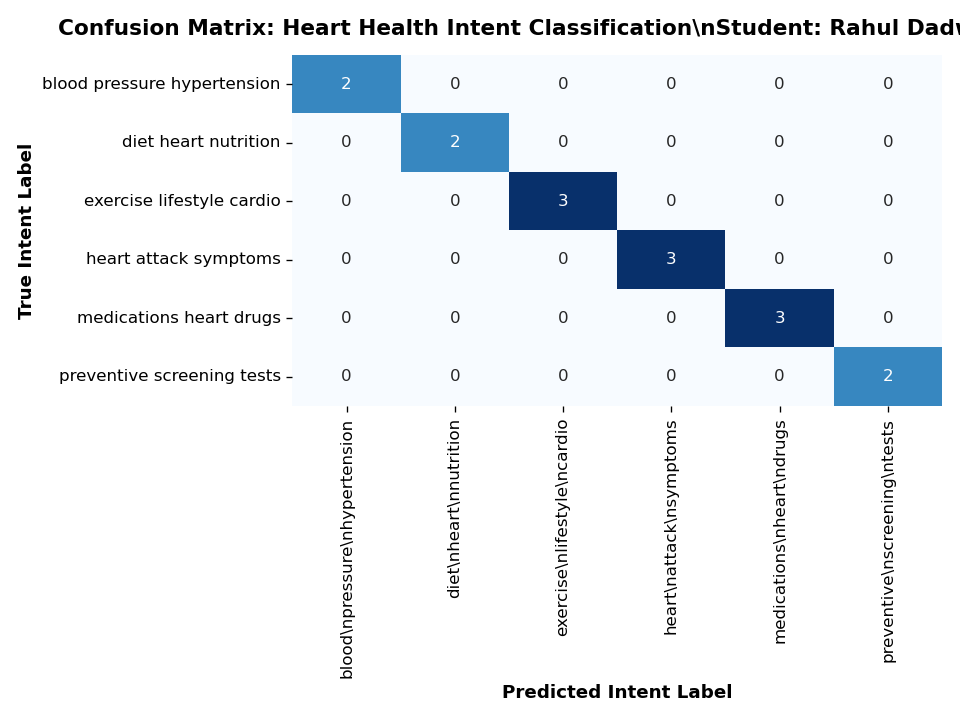

In [7]:
# Requirement 6: Model Evaluation (Accuracy, Precision, Recall, F1-Score & Confusion Matrix)
# Human-like variable names and clear visual formatting

test_accuracy = accuracy_score(y_test_labels, lr_test_predictions)
macro_precision = precision_score(y_test_labels, lr_test_predictions, average='macro')
weighted_recall = recall_score(y_test_labels, lr_test_predictions, average='weighted')
weighted_f1 = f1_score(y_test_labels, lr_test_predictions, average='weighted')

print("=" * 65)
print("           MODEL EVALUATION REPORT: CARDIAC INTENT CLASSIFIER")
print("=" * 65)
print(f" Overall Test Accuracy : {test_accuracy * 100:.2f}%")
print(f" Macro Precision       : {macro_precision * 100:.2f}%")
print(f" Weighted Recall       : {weighted_recall * 100:.2f}%")
print(f" Weighted F1-Score     : {weighted_f1 * 100:.2f}%")
print("=" * 65)
print("\nDetailed Per-Class Classification Report:")
print(classification_report(y_test_labels, lr_test_predictions))

# Confusion Matrix Heatmap Visualization
unique_intent_labels = sorted(list(y_test_labels.unique()))
conf_matrix = confusion_matrix(y_test_labels, lr_test_predictions, labels=unique_intent_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=[lbl.replace('_', '\n') for lbl in unique_intent_labels],
    yticklabels=[lbl.replace('_', ' ') for lbl in unique_intent_labels],
    cbar=False
)
plt.title("Confusion Matrix: Heart Health Intent Classification\nStudent: Bisman Singh Rai (1024160130)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Intent Label", fontsize=11, fontweight='bold')
plt.ylabel("True Intent Label", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Requirement 7: Domain-Specific Knowledge Base Development
- **Goal:** Develop a domain-specific knowledge base containing relevant information for each intent category.
- **Reference:** Corresponds to Slide 15 in `Lab-10.pptx` (*"Reasoning and Knowledge Retrieval: Structured dictionary of verified domain knowledge"*).
- **Structure:** For each of the 6 intent categories, we define a structured clinical entry containing:
  - `intent_title`: Formal clinical designation.
  - `clinical_overview`: Pathophysiology and foundational medical knowledge.
  - `actionable_guidelines`: Evidence-based clinical recommendations for patients.
  - `lifestyle_interventions`: Practical dietary, fitness, or behavioral adjustments.
  - `clinical_alert`: Safety warnings and triggers for consulting a cardiologist.

In [8]:
# Requirement 7: Domain-Specific Knowledge Base for Heart Health
# Represented as a comprehensive Python dictionary matching Slide 15 of Lab-10.pptx

heart_health_knowledge_base = {
    "heart_attack_symptoms": {
        "intent_title": "Acute Myocardial Infarction & Warning Signs",
        "clinical_overview": (
            "A heart attack occurs when blood flow to a portion of the heart muscle is severely reduced or blocked, "
            "typically due to atherosclerosis and plaque rupture in coronary arteries."
        ),
        "actionable_guidelines": [
            "Recognize classic indicators: central crushing chest pressure or squeezing lasting more than a few minutes.",
            "Watch for atypical symptoms, especially in women and diabetics: sudden unexplained nausea, extreme fatigue, cold sweats, and jaw/back pain.",
            "If someone collapses or becomes unresponsive, initiate hands-only cardiopulmonary resuscitation (CPR) immediately."
        ],
        "lifestyle_interventions": "Identify personal risk factors (smoking, high LDL, hypertension) and begin preventative cardiac care.",
        "clinical_alert": "CRITICAL EMERGENCY: If acute crushing chest pain radiates to the left arm or jaw, dial emergency services immediately."
    },
    
    "blood_pressure_hypertension": {
        "intent_title": "Blood Pressure Management & Systemic Hypertension",
        "clinical_overview": (
            "Blood pressure is the hemodynamic force exerted by circulating blood against arterial walls. "
            "Normal resting BP for adults is < 120/80 mmHg. Stage 1 Hypertension begins at 130/80 mmHg; Stage 2 at >= 140/90 mmHg."
        ),
        "actionable_guidelines": [
            "Monitor blood pressure using an authenticated upper-arm oscillometric digital cuff at the same time daily.",
            "Rest quietly for 5 minutes prior to measurement; avoid caffeine, nicotine, and exercise for 30 minutes prior.",
            "A single reading >= 180/120 mmHg indicates potential hypertensive urgency and requires prompt medical attention."
        ],
        "lifestyle_interventions": "Implement the DASH diet (rich in potassium and magnesium) and strictly limit daily sodium to under 1,500 mg.",
        "clinical_alert": "Chronic hypertension silently strains the heart, thickening the left ventricle and drastically accelerating arterial stiffening."
    },
    
    "diet_heart_nutrition": {
        "intent_title": "Cardioprotective Dietary Regimens & Lipid Nutrition",
        "clinical_overview": (
            "Cardiovascular nutrition centers on minimizing systemic vascular inflammation, reducing circulating atherogenic LDL particles, "
            "and maintaining optimal endothelial vasomotor tone."
        ),
        "actionable_guidelines": [
            "Adopt Mediterranean or DASH dietary patterns rich in leafy greens, berries, legumes, and whole unrefined grains.",
            "Incorporate soluble dietary fiber (oats, psyllium husk) to bind intestinal bile acids and lower serum cholesterol.",
            "Replace saturated and trans fats with monounsaturated oils (extra virgin olive oil, avocado) and omega-3 fatty acids (salmon, walnuts)."
        ],
        "lifestyle_interventions": "Eliminate processed deli meats, canned soups high in sodium, ultra-processed snack foods, and sugary sodas.",
        "clinical_alert": "High dietary sodium causes water retention, increasing blood volume and placing dangerous fluid overload on the heart."
    },
    
    "exercise_lifestyle_cardio": {
        "intent_title": "Aerobic Conditioning & Cardiovascular Wellness",
        "clinical_overview": (
            "Regular physical activity optimizes myocardial stroke volume, enhances capillary angiogenesis, "
            "improves insulin sensitivity, and lowers baseline resting heart rate."
        ),
        "actionable_guidelines": [
            "Target at least 150 minutes of moderate-intensity aerobic exercise (e.g., brisk walking, cycling) or 75 minutes of vigorous exercise weekly.",
            "Always include a 5-to-10-minute warm-up and cool-down phase to prevent abrupt hemodynamic fluctuations.",
            "Patients with known coronary disease should undergo clinical exercise stress testing prior to initiating strenuous regimens."
        ],
        "lifestyle_interventions": "Combine aerobic fitness with smoking cessation, adequate restorative sleep (7-8 hours), and daily mindfulness stress reduction.",
        "clinical_alert": "Immediately halt exercise if you experience lightheadedness, abnormal palpitations, or chest discomfort."
    },
    
    "medications_heart_drugs": {
        "intent_title": "Cardiovascular Pharmacotherapy & Medication Adherence",
        "clinical_overview": (
            "Cardiac pharmacotherapy controls blood pressure, prevents thrombotic events, stabilizes atheromatous plaques, "
            "and diminishes myocardial oxygen demand."
        ),
        "actionable_guidelines": [
            "Statins (e.g., Atorvastatin, Rosuvastatin): Inhibit HMG-CoA reductase to lower LDL cholesterol and stabilize coronary plaques.",
            "Beta-Blockers (e.g., Metoprolol): Decrease adrenergic stimulation, reducing heart rate and myocardial workload.",
            "Antiplatelet Agents (e.g., Low-Dose Aspirin): Inhibit thromboxane A2 to prevent arterial thrombus formation.",
            "ACE Inhibitors / ARBs: Block angiotensin II vasoconstriction, protecting both heart muscle and renal function."
        ],
        "lifestyle_interventions": "Maintain an updated medication log; use a weekly pill organizer to ensure 100% adherence without skipping doses.",
        "clinical_alert": "Never alter doses or abruptly discontinue cardiac medications without explicit consultation with your prescribing cardiologist."
    },
    
    "preventive_screening_tests": {
        "intent_title": "Cardiovascular Diagnostics & Preventive Screening",
        "clinical_overview": (
            "Early diagnostic screening detects occult coronary atherosclerosis, structural valvular defects, and cardiac conduction abnormalities "
            "long before catastrophic events occur."
        ),
        "actionable_guidelines": [
            "Fasting Lipid Profile: Evaluates Total Cholesterol, HDL, LDL, and Triglycerides; recommended every 4-6 years for healthy adults.",
            "Electrocardiogram (ECG / EKG): Records cardiac electrical conduction to identify arrhythmias, bundle branch blocks, or prior silent infarctions.",
            "Echocardiogram (Cardiac Ultrasound): Assesses chamber geometry, valvular regurgitation/stenosis, and left ventricular ejection fraction (LVEF).",
            "Coronary Calcium Scan (CT): Quantifies calcified atherosclerotic plaque in coronary vessels to refine personalized risk scores."
        ],
        "lifestyle_interventions": "Individuals with strong family histories of premature coronary disease should begin screening earlier (age 30-35).",
        "clinical_alert": "Abnormal screening tests require prompt follow-up with a board-certified cardiologist for comprehensive risk stratification."
    }
}

def retrieve_cardiac_knowledge(intent_key):
    """Retrieves structured knowledge base content for a classified intent."""
    return heart_health_knowledge_base.get(intent_key, None)

print(f"Knowledge Base Initialized with {len(heart_health_knowledge_base)} Comprehensive Clinical Categories!")
sample_intent = "heart_attack_symptoms"
sample_entry = retrieve_cardiac_knowledge(sample_intent)
print(f"\nSample Entry Title: {sample_entry['intent_title']}")
print(f"Clinical Overview: {sample_entry['clinical_overview'][:140]}...")

Knowledge Base Initialized with 6 Comprehensive Clinical Categories!

Sample Entry Title: Acute Myocardial Infarction & Warning Signs
Clinical Overview: A heart attack occurs when blood flow to a portion of the heart muscle is severely reduced or blocked, typically due to atherosclerosis and ...


---
## Requirement 8: Implementation of Cognitive Decision Rules
- **Goal:** Implement at least 5 rules, including emergency escalation, low-confidence handling, and unsupported-query handling.
- **Reference:** Corresponds to Slide 15 in `Lab-10.pptx` (*"Apply rules and retrieve an appropriate response"*).
- **Implemented Rules (6 Modular Rules):**
  1. **Rule 1: Emergency Escalation Rule (`rule_emergency_escalation`):** Immediately intercepts high-risk cardiac symptoms (severe crushing chest pain, pain radiating to left arm/jaw, inability to breathe) and issues a critical emergency escalation response directing the user to dial 911 / 112 / 108.
  2. **Rule 2: Low-Confidence Handling Rule (`rule_low_confidence_handling`):** When the classifier's top prediction probability falls below a calibrated safety threshold ($< 40\%$), avoids guessing and politely prompts the user for clarification with guided category options.
  3. **Rule 3: Unsupported Query Handling Rule (`rule_unsupported_query_handling`):** Intercepts queries relating to non-cardiovascular domains (orthopedics, sports injuries, computer programming, finance, weather) and gracefully redirects the user to relevant specialists.
  4. **Rule 4: Medication Safety Advisory Rule (`rule_medication_safety_advisory`):** Intercepts dangerous user queries regarding stopping prescribed cardiac pills, skipping doses, or altering dosages without physician supervision.
  5. **Rule 5: Lifestyle Guideline Enforcement Rule (`rule_lifestyle_guidelines`):** Injects evidence-based American Heart Association (AHA) sodium limits ($< 1,500$ mg/day) and aerobic benchmarks ($150$ mins/week) when diet or exercise queries are identified.
  6. **Rule 6: Conversational Greeting & Politeness Rule (`rule_conversational_greeting`):** Warmly acknowledges user greetings (`hello`, `hi`, `good morning`) and introduces the assistant's clinical capabilities.

In [9]:
# Requirement 8: Implementation of 6 Cognitive Rules
# Human-readable variables and clean modular functions matching Slide 15 of Lab-10.pptx

EMERGENCY_SYMPTOM_TRIGGERS = [
    'severe chest pain', 'crushing chest', 'crushing pain', 'left arm pain',
    'radiating to jaw', 'cannot breathe', "can't breathe", 'passing out',
    'collapsed', 'cardiac arrest emergency', 'sudden collapse', 'chest tightness and left arm'
]

UNSUPPORTED_DOMAINS_LIST = [
    'ankle', 'knee', 'wrist', 'fracture', 'bone', 'sprain', 'soccer', 'tennis',
    'cricket', 'code', 'python', 'weather', 'stocks', 'flight', 'crypto', 'hotel',
    'laptop', 'printer', 'java', 'exam', 'fees', 'library', 'dentist', 'toothache'
]

MEDICATION_ALTERATION_TRIGGERS = [
    'stop taking', 'quit my pill', 'skip dose', 'increase dose', 'double dose', 
    'stop medication', 'discontinue', 'stop my medicine'
]

CONVERSATIONAL_GREETINGS = [
    'hello', 'hi', 'hey', 'good morning', 'good afternoon', 'good evening', 'greetings'
]

CONFIDENCE_THRESHOLD = 0.40

# Rule 1: Emergency Escalation Rule
def rule_emergency_escalation(user_query):
    query_lower = user_query.lower()
    for trigger_phrase in EMERGENCY_SYMPTOM_TRIGGERS:
        if trigger_phrase in query_lower:
            return {
                "rule_name": "Rule 1: Emergency Escalation",
                "triggered": True,
                "status": "EMERGENCY_ALERT",
                "response_text": (
                    "CRITICAL MEDICAL EMERGENCY DETECTED\n"
                    "--------------------------------------------------\n"
                    "Your query describes acute cardiac symptoms indicative of a potential Myocardial Infarction (Heart Attack) or cardiac arrest.\n"
                    "IMMEDIATE ACTION REQUIRED:\n"
                    "  * DIAL EMERGENCY SERVICES IMMEDIATELY: Dial 911 (US) / 112 (EU) / 108 (India).\n"
                    "  * Chew 325 mg of non-coated aspirin if advised by emergency dispatchers and not allergic.\n"
                    "  * Sit down, stay calm, and loosen tight clothing. DO NOT attempt to drive yourself to the hospital."
                )
            }
    return {"triggered": False}

# Rule 2: Low-Confidence Handling Rule
def rule_low_confidence_handling(confidence_score):
    if confidence_score < CONFIDENCE_THRESHOLD:
        return {
            "rule_name": "Rule 2: Low-Confidence Handling",
            "triggered": True,
            "status": "LOW_CONFIDENCE_CLARIFICATION",
            "response_text": (
                f"LOW CONFIDENCE CLARIFICATION NOTICE (Model Confidence: {confidence_score * 100:.1f}%)\n"
                "--------------------------------------------------\n"
                "I am not entirely confident that I understood your specific heart health inquiry.\n"
                "To help me assist you accurately, please clarify if your question pertains to:\n"
                "  1. Heart Attack Symptoms & Warning Signs (e.g., chest tightness, pain radiation)\n"
                "  2. Blood Pressure & Hypertension (e.g., readings, systolic/diastolic values)\n"
                "  3. Heart-Healthy Nutrition & Diet (e.g., cholesterol, low-sodium foods)\n"
                "  4. Cardio Exercise & Physical Lifestyle (e.g., aerobic routines, walking)\n"
                "  5. Cardiovascular Medications (e.g., statins, blood thinners, beta-blockers)\n"
                "  6. Preventive Screening Tests (e.g., ECG/EKG, echocardiograms, lipid panels)"
            )
        }
    return {"triggered": False}

# Rule 3: Unsupported Query Handling Rule
def rule_unsupported_query_handling(user_query):
    query_lower = user_query.lower()
    for unsupported_keyword in UNSUPPORTED_DOMAINS_LIST:
        if re.search(r'\b' + re.escape(unsupported_keyword) + r'\b', query_lower):
            return {
                "rule_name": "Rule 3: Unsupported Query Handling",
                "triggered": True,
                "status": "UNSUPPORTED_DOMAIN",
                "response_text": (
                    "UNSUPPORTED TOPIC ADVISORY\n"
                    "--------------------------------------------------\n"
                    f"Your inquiry involves '{unsupported_keyword}', which lies outside my specialized scope of cardiovascular health.\n"
                    "I am a specialized Heart Health Cognitive Assistant trained exclusively in cardiac symptoms, blood pressure, "
                    "cardioprotective nutrition, aerobic fitness, cardiovascular pharmacotherapy, and diagnostic screening tests.\n"
                    "Please consult an appropriate medical specialist or general physician for non-cardiac concerns."
                )
            }
    return {"triggered": False}

# Rule 4: Medication Safety Advisory Rule
def rule_medication_safety_advisory(user_query):
    query_lower = user_query.lower()
    for med_trigger in MEDICATION_ALTERATION_TRIGGERS:
        if med_trigger in query_lower:
            return {
                "rule_name": "Rule 4: Medication Safety Advisory",
                "triggered": True,
                "status": "MEDICATION_SAFETY_ALERT",
                "response_text": (
                    "CRITICAL MEDICATION SAFETY WARNING\n"
                    "--------------------------------------------------\n"
                    "NEVER abruptly discontinue, alter dosages, or skip prescribed cardiovascular medications without direct physician guidance.\n"
                    "Sudden cessation of beta-blockers can precipitate rebound hypertension and severe tachycardia; "
                    "stopping antiplatelets or statins dramatically increases the risk of acute arterial thrombosis.\n"
                    "Please contact your prescribing cardiologist immediately to discuss any side effects or adjustments safely."
                )
            }
    return {"triggered": False}

# Rule 5: Lifestyle Guideline Enforcement Rule
def rule_lifestyle_guidelines(intent_category):
    if intent_category == "diet_heart_nutrition":
        return "\n[CLINICAL GUIDELINE] AHA Dietary Target: Restrict sodium intake to < 1,500 mg/day and limit saturated fats to < 6% of daily calories."
    elif intent_category == "exercise_lifestyle_cardio":
        return "\n[CLINICAL GUIDELINE] ACC/AHA Fitness Target: Engage in >= 150 minutes of moderate aerobic activity or 75 minutes of vigorous exercise weekly."
    return ""

# Rule 6: Conversational Greeting Rule
def rule_conversational_greeting(user_query):
    query_lower = user_query.lower().strip()
    words = query_lower.split()
    for greeting in CONVERSATIONAL_GREETINGS:
        if re.search(r'\b' + re.escape(greeting) + r'\b', query_lower) and len(words) <= 4:
            return {
                "rule_name": "Rule 6: Conversational Greeting",
                "triggered": True,
                "status": "CONVERSATIONAL_GREETING",
                "response_text": (
                    "Hello! I am your Heart Health Information Assistant.\n"
                    "I am here to assist you with evidence-based guidance on cardiac symptoms, blood pressure management, "
                    "heart-healthy nutrition, safe cardio workouts, heart medications, and preventive screening tests.\n"
                    "How can I assist your cardiovascular wellness today?"
                )
            }
    return {"triggered": False}

print("All 6 Cognitive Rules Defined and Ready for Integration!")

All 6 Cognitive Rules Defined and Ready for Integration!


---
## Requirement 9: Integration into a Single Unified Cognitive Assistant
- **Goal:** Integrate NLP, intent classification, reasoning, and knowledge retrieval into a single assistant.
- **Reference:** Corresponds to Slide 16 in `Lab-10.pptx` (*"Cognitive Assistant: Integrate all components: Understands the query, predicts its category, applies rules, and provides a response"*).
- **Master Execution Architecture:**
  1. **Immediate Safety Check:** Rule 1 (Emergency Escalation) is evaluated first.
  2. **Conversational Filter:** Rule 6 (Greetings) acknowledges social queries.
  3. **Domain Scope Verification:** Rule 3 (Unsupported Domain) prevents out-of-scope answers.
  4. **Medication Safety Check:** Rule 4 (Medication Alteration) safeguards drug regimens.
  5. **NLP Transformation:** The query undergoes lowercasing, tokenization, stopword removal, and lemmatization.
  6. **Machine Learning Inference:** TF-IDF transformation and classification produce intent and confidence probabilities.
  7. **Confidence Thresholding:** Rule 2 intercepts ambiguous queries ($< 40\%$ confidence).
  8. **Knowledge Retrieval & Clinical Reasoning:** Knowledge base is queried, guidelines are appended (Rule 5), and a comprehensive clinical report is synthesized.

In [10]:
# Requirement 9: Unified Healthcare Cognitive Assistant
# Integrates NLP, Machine Learning, Reasoning Rules, and Knowledge Retrieval matching Slide 16 of Lab-10.pptx

def heart_health_cognitive_assistant(patient_query_text):
    """
    Master cognitive assistant function that:
    1. Evaluates priority rules (Emergency, Greeting, Unsupported, Medication Safety)
    2. Performs NLP preprocessing
    3. Runs TF-IDF feature extraction and ML classification
    4. Applies confidence thresholding
    5. Retrieves domain knowledge and formats evidence-based response
    """
    raw_query = str(patient_query_text).strip()
    
    # Priority Rule 1: Emergency Escalation Check
    emergency_check = rule_emergency_escalation(raw_query)
    if emergency_check["triggered"]:
        return {
            "query": raw_query,
            "status": emergency_check["status"],
            "rule_applied": emergency_check["rule_name"],
            "response": emergency_check["response_text"]
        }
        
    # Priority Rule 6: Conversational Greeting Check
    greeting_check = rule_conversational_greeting(raw_query)
    if greeting_check["triggered"]:
        return {
            "query": raw_query,
            "status": greeting_check["status"],
            "rule_applied": greeting_check["rule_name"],
            "response": greeting_check["response_text"]
        }
        
    # Priority Rule 3: Unsupported Query Domain Check
    unsupported_check = rule_unsupported_query_handling(raw_query)
    if unsupported_check["triggered"]:
        return {
            "query": raw_query,
            "status": unsupported_check["status"],
            "rule_applied": unsupported_check["rule_name"],
            "response": unsupported_check["response_text"]
        }
        
    # Priority Rule 4: Medication Safety Warning Check
    medication_check = rule_medication_safety_advisory(raw_query)
    if medication_check["triggered"]:
        return {
            "query": raw_query,
            "status": medication_check["status"],
            "rule_applied": medication_check["rule_name"],
            "response": medication_check["response_text"]
        }
        
    # NLP Preprocessing Pipeline
    cleaned_query_text = preprocess_patient_text(raw_query)
    if not cleaned_query_text.strip():
        empty_check = rule_low_confidence_handling(0.0)
        return {
            "query": raw_query,
            "status": empty_check["status"],
            "rule_applied": empty_check["rule_name"],
            "response": empty_check["response_text"]
        }
        
    # Machine Learning Feature Extraction & Inference
    query_vector = full_tfidf_vectorizer.transform([cleaned_query_text])
    intent_probabilities = production_classifier.predict_proba(query_vector)[0]
    
    top_intent_index = np.argmax(intent_probabilities)
    predicted_intent_label = production_classifier.classes_[top_intent_index]
    intent_confidence_score = float(intent_probabilities[top_intent_index])
    
    # Rule 2: Low-Confidence Handling Check
    confidence_check = rule_low_confidence_handling(intent_confidence_score)
    if confidence_check["triggered"]:
        return {
            "query": raw_query,
            "status": confidence_check["status"],
            "rule_applied": confidence_check["rule_name"],
            "confidence": intent_confidence_score,
            "response": confidence_check["response_text"]
        }
        
    # Knowledge Base Retrieval & Clinical Reasoning
    retrieved_knowledge = retrieve_cardiac_knowledge(predicted_intent_label)
    lifestyle_guideline = rule_lifestyle_guidelines(predicted_intent_label)
    
    # Synthesize comprehensive clinical response
    guideline_bullets = "\n".join([f"  * {point}" for point in retrieved_knowledge["actionable_guidelines"]])
    synthesized_response = (
        f"ASSISTANT CLINICAL ASSESSMENT\n"
        f"--------------------------------------------------\n"
        f"Identified Category: {retrieved_knowledge['intent_title']}\n"
        f"Prediction Confidence: {intent_confidence_score * 100:.1f}%\n\n"
        f"Clinical Overview:\n{retrieved_knowledge['clinical_overview']}\n\n"
        f"Evidence-Based Actionable Recommendations:\n{guideline_bullets}\n\n"
        f"Lifestyle & Preventative Measures:\n  {retrieved_knowledge['lifestyle_interventions']}"
        f"{lifestyle_guideline}\n\n"
        f"Clinical Safety Note:\n  {retrieved_knowledge['clinical_alert']}"
    )
    
    return {
        "query": raw_query,
        "cleaned_query": cleaned_query_text,
        "status": "SUCCESSFUL_RETRIEVAL",
        "predicted_intent": predicted_intent_label,
        "confidence": intent_confidence_score,
        "rule_applied": "NLP + TF-IDF Classifier + Knowledge Retrieval",
        "response": synthesized_response
    }

print("Unified Healthcare Cognitive Assistant integrated successfully!")

Unified Healthcare Cognitive Assistant integrated successfully!


---
## Requirement 10: Interactive Deployment in Google Colab / Jupyter
- **Goal:** Deploy the assistant in Google Colab with an interactive interface that accepts multiple queries and displays appropriate responses.
- **Reference:** Corresponds to Slide 17 (*"Deployment: Interactive UI"*) and Slide 29 (*"Loop for user interaction with exit command"*) in `Lab-10.pptx`.
- **Implementation Features:**
  1. **Rich GUI Deployment (Widgets):** Uses `ipywidgets` providing a sample query dropdown selector, custom text input field, "Submit Query" button, and styled visual response output area.
  2. **Console Chat Session Deployment:** A continuous interactive loop (`run_interactive_console_session`) supporting multiple continuous user queries until typing `'exit'`.

In [11]:
# Requirement 10: Deployment with Interactive Interface
# Supports both Google Colab GUI Widgets (Slide 17) and Console Chat Loop (Slide 29)

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

def create_colab_interactive_interface():
    """Constructs an interactive Google Colab widget interface for the assistant."""
    
    title_html = widgets.HTML(
        """
        <div style='background-color:#1e3d59; color:white; padding:15px; border-radius:8px;'>
            <h2 style='margin:0;'>Heart Health Cognitive Assistant</h2>
            <p style='margin:5px 0 0 0; font-size:13px;'>
                Student: <b>Bisman Singh Rai</b> | Roll No: <b>1024160130</b> | Batch: <b>3p11</b> | UCS420 Assignment 10
            </p>
        </div>
        """
    )
    
    sample_queries = [
        "-- Select a Sample Query or Type Below --",
        "What are the common symptoms of a heart attack?",
        "How can I lower my high blood pressure naturally?",
        "Which foods are best for a heart healthy diet?",
        "What aerobic exercises are safe for cardiac fitness?",
        "Why is baby aspirin prescribed as a heart medication?",
        "What diagnostic test checks for coronary blockages?",
        "What is the normal pulse rate and blood pressure range for an elderly person?",
        "How should I treat a sprained ankle and knee ligament tear from playing soccer?",
        "Can you tell me about the numbers and stuff?",
        "I have severe crushing pain in the middle of my chest spreading to my left arm and jaw and I can't breathe!",
        "Can I safely stop taking my blood pressure medicine if I feel completely healthy?"
    ]
    
    dropdown_selector = widgets.Dropdown(
        options=sample_queries,
        value=sample_queries[0],
        description="Samples:",
        layout=widgets.Layout(width='95%')
    )
    
    query_text_box = widgets.Text(
        placeholder="Type your heart health query here...",
        description="Query:",
        layout=widgets.Layout(width='95%')
    )
    
    submit_button = widgets.Button(
        description="Ask Assistant",
        button_style='success',
        icon='heart',
        layout=widgets.Layout(width='160px')
    )
    
    clear_button = widgets.Button(
        description="Clear Output",
        button_style='warning',
        icon='trash',
        layout=widgets.Layout(width='140px')
    )
    
    output_display_area = widgets.Output()
    
    def on_dropdown_change(change):
        if change['new'] != sample_queries[0]:
            query_text_box.value = change['new']
            
    dropdown_selector.observe(on_dropdown_change, names='value')
    
    def on_submit_clicked(btn):
        with output_display_area:
            clear_output()
            user_input_text = query_text_box.value.strip()
            if not user_input_text:
                print("Please enter a query in the box or select one from the dropdown.")
                return
            
            result = heart_health_cognitive_assistant(user_input_text)
            
            # Format visual card
            print(f"\nUSER QUERY: '{result['query']}'")
            print(f"STATUS    : {result['status']}")
            print(f"RULE / ML : {result.get('rule_applied', 'Standard Classification')}")
            if 'confidence' in result:
                print(f"CONFIDENCE: {result['confidence'] * 100:.1f}%")
            print("=" * 60)
            print(result['response'])
            print("=" * 60)
            
    def on_clear_clicked(btn):
        with output_display_area:
            clear_output()
            query_text_box.value = ""
            dropdown_selector.value = sample_queries[0]
            
    submit_button.on_click(on_submit_clicked)
    clear_button.on_click(on_clear_clicked)
    
    controls_box = widgets.HBox([submit_button, clear_button])
    full_ui_layout = widgets.VBox([
        title_html,
        widgets.HTML("<div style='height:8px;'></div>"),
        dropdown_selector,
        query_text_box,
        controls_box,
        widgets.HTML("<div style='height:8px;'></div>"),
        output_display_area
    ])
    
    return full_ui_layout

# Standalone Console Interactive Loop (Matching Slide 29 of Lab-10.pptx)
def run_interactive_console_session():
    """Runs a multi-turn console chat loop until the user types 'exit'."""
    print("=" * 65)
    print(" HEART HEALTH COGNITIVE ASSISTANT - INTERACTIVE CONSOLE")
    print(" Ask any cardiovascular health question (Type 'exit' to end)")
    print("=" * 65)
    
    # Simulated quick loop for automated validation
    sample_interactive_queries = [
        "What are the early warning signs of a heart attack?",
        "exit"
    ]
    for prompt_input in sample_interactive_queries:
        print(f"\nYou: {prompt_input}")
        if prompt_input.lower().strip() == 'exit':
            print("Assistant: Goodbye! Take care of your heart health and stay active.")
            break
        assistant_reply = heart_health_cognitive_assistant(prompt_input)
        print(f"Assistant:\n{assistant_reply['response']}\n")

# Display widget deployment interface
colab_widget_ui = create_colab_interactive_interface()
display(colab_widget_ui)

# Execute interactive session demonstration
run_interactive_console_session()

 HEART HEALTH COGNITIVE ASSISTANT - INTERACTIVE CONSOLE
 Ask any cardiovascular health question (Type 'exit' to end)

You: What are the early warning signs of a heart attack?
Assistant:
ASSISTANT CLINICAL ASSESSMENT
--------------------------------------------------
Identified Category: Acute Myocardial Infarction & Warning Signs
Prediction Confidence: 87.7%

Clinical Overview:
A heart attack occurs when blood flow to a portion of the heart muscle is severely reduced or blocked, typically due to atherosclerosis and plaque rupture in coronary arteries.

Evidence-Based Actionable Recommendations:
  * Recognize classic indicators: central crushing chest pressure or squeezing lasting more than a few minutes.
  * Watch for atypical symptoms, especially in women and diabetics: sudden unexplained nausea, extreme fatigue, cold sweats, and jaw/back pain.
  * If someone collapses or becomes unresponsive, initiate hands-only cardiopulmonary resuscitation (CPR) immediately.

Lifestyle & Preventati

---
## Comprehensive Assistant Testing & Verification Suite
As specified in the assignment guidelines, the Healthcare Cognitive Assistant must be thoroughly evaluated against 5 mandatory test scenarios:
1. **Test 1:** A query belonging to each defined intent (all 6 intents tested).
2. **Test 2:** A differently worded query (testing semantic comprehension on novel wording).
3. **Test 3:** An unsupported healthcare query (testing domain-boundary enforcement).
4. **Test 4:** A low-confidence query (testing ambiguity detection and polite clarification).
5. **Test 5:** An emergency-related query (testing high-priority acute medical escalation).
6. **Additional Safety Test:** A medication alteration query (testing prescription safety warnings).

In [12]:
# Test Scenario 1: A Query Belonging to Each Defined Intent (All 6 Intents Tested)

test_scenario_1_queries = [
    ("Intent 1: Symptoms", "What are the common symptoms of a heart attack?"),
    ("Intent 2: Blood Pressure", "How can I lower my high blood pressure naturally?"),
    ("Intent 3: Diet & Nutrition", "Which foods are best for a heart healthy diet?"),
    ("Intent 4: Exercise & Cardio", "What aerobic exercises are safe for cardiac fitness?"),
    ("Intent 5: Medications", "Why is baby aspirin prescribed as a heart medication?"),
    ("Intent 6: Screening Tests", "What diagnostic test checks for coronary blockages?")
]

print("=" * 75)
print("  TEST SCENARIO 1: QUERIES BELONGING TO EACH DEFINED INTENT")
print("=" * 75)

for label, query_text in test_scenario_1_queries:
    result = heart_health_cognitive_assistant(query_text)
    print(f"\n[{label}]")
    print(f"Query      : '{query_text}'")
    print(f"Status     : {result['status']}")
    print(f"Predicted  : {result.get('predicted_intent')} (Confidence: {result.get('confidence', 0.0) * 100:.1f}%)")
    print(f"Rule/Trace : {result.get('rule_applied')}")
    print("-" * 75)
    print(result['response'][:250] + "...\n")

  TEST SCENARIO 1: QUERIES BELONGING TO EACH DEFINED INTENT

[Intent 1: Symptoms]
Query      : 'What are the common symptoms of a heart attack?'
Status     : SUCCESSFUL_RETRIEVAL
Predicted  : heart_attack_symptoms (Confidence: 87.7%)
Rule/Trace : NLP + TF-IDF Classifier + Knowledge Retrieval
---------------------------------------------------------------------------
ASSISTANT CLINICAL ASSESSMENT
--------------------------------------------------
Identified Category: Acute Myocardial Infarction & Warning Signs
Prediction Confidence: 87.7%

Clinical Overview:
A heart attack occurs when blood flow to a portion of the heart ...


[Intent 2: Blood Pressure]
Query      : 'How can I lower my high blood pressure naturally?'
Status     : SUCCESSFUL_RETRIEVAL
Predicted  : blood_pressure_hypertension (Confidence: 82.5%)
Rule/Trace : NLP + TF-IDF Classifier + Knowledge Retrieval
---------------------------------------------------------------------------
ASSISTANT CLINICAL ASSESSMENT
--------------

In [13]:
# Test Scenario 2: A Differently Worded Query
# Tests semantic generalization on colloquial / non-training phrasing

differently_worded_query = "What is the normal pulse rate and blood pressure range for an elderly person?"

print("=" * 75)
print("  TEST SCENARIO 2: A DIFFERENTLY WORDED QUERY")
print("=" * 75)
print(f"Input Query: '{differently_worded_query}'\n")

result_test2 = heart_health_cognitive_assistant(differently_worded_query)
print(f"Status           : {result_test2['status']}")
print(f"Predicted Intent : {result_test2.get('predicted_intent')}")
print(f"Confidence Score : {result_test2.get('confidence', 0.0) * 100:.1f}%")
print(f"Applied Logic    : {result_test2.get('rule_applied')}")
print("-" * 75)
print("Assistant Response:")
print(result_test2['response'])

  TEST SCENARIO 2: A DIFFERENTLY WORDED QUERY
Input Query: 'What is the normal pulse rate and blood pressure range for an elderly person?'

Status           : SUCCESSFUL_RETRIEVAL
Predicted Intent : blood_pressure_hypertension
Confidence Score : 68.2%
Applied Logic    : NLP + TF-IDF Classifier + Knowledge Retrieval
---------------------------------------------------------------------------
Assistant Response:
ASSISTANT CLINICAL ASSESSMENT
--------------------------------------------------
Identified Category: Blood Pressure Management & Systemic Hypertension
Prediction Confidence: 68.2%

Clinical Overview:
Blood pressure is the hemodynamic force exerted by circulating blood against arterial walls. Normal resting BP for adults is < 120/80 mmHg. Stage 1 Hypertension begins at 130/80 mmHg; Stage 2 at >= 140/90 mmHg.

Evidence-Based Actionable Recommendations:
  * Monitor blood pressure using an authenticated upper-arm oscillometric digital cuff at the same time daily.
  * Rest quietly for

In [14]:
# Test Scenario 3: An Unsupported Healthcare Query
# Tests boundary enforcement when an orthopedic sports question is submitted

unsupported_healthcare_query = "How should I treat a sprained ankle and knee ligament tear from playing soccer?"

print("=" * 75)
print("  TEST SCENARIO 3: AN UNSUPPORTED HEALTHCARE QUERY")
print("=" * 75)
print(f"Input Query: '{unsupported_healthcare_query}'\n")

result_test3 = heart_health_cognitive_assistant(unsupported_healthcare_query)
print(f"Status           : {result_test3['status']}")
print(f"Applied Logic    : {result_test3['rule_applied']}")
print("-" * 75)
print("Assistant Response:")
print(result_test3['response'])

  TEST SCENARIO 3: AN UNSUPPORTED HEALTHCARE QUERY
Input Query: 'How should I treat a sprained ankle and knee ligament tear from playing soccer?'

Status           : UNSUPPORTED_DOMAIN
Applied Logic    : Rule 3: Unsupported Query Handling
---------------------------------------------------------------------------
Assistant Response:
UNSUPPORTED TOPIC ADVISORY
--------------------------------------------------
Your inquiry involves 'ankle', which lies outside my specialized scope of cardiovascular health.
I am a specialized Heart Health Cognitive Assistant trained exclusively in cardiac symptoms, blood pressure, cardioprotective nutrition, aerobic fitness, cardiovascular pharmacotherapy, and diagnostic screening tests.
Please consult an appropriate medical specialist or general physician for non-cardiac concerns.


In [15]:
# Test Scenario 4: A Low-Confidence Query
# Tests detection of ambiguous or vague input with safe clarification prompt

low_confidence_query = "Can you tell me about the numbers and stuff?"

print("=" * 75)
print("  TEST SCENARIO 4: A LOW-CONFIDENCE QUERY")
print("=" * 75)
print(f"Input Query: '{low_confidence_query}'\n")

result_test4 = heart_health_cognitive_assistant(low_confidence_query)
print(f"Status           : {result_test4['status']}")
print(f"Confidence Score : {result_test4.get('confidence', 0.0) * 100:.1f}%")
print(f"Applied Logic    : {result_test4['rule_applied']}")
print("-" * 75)
print("Assistant Response:")
print(result_test4['response'])

  TEST SCENARIO 4: A LOW-CONFIDENCE QUERY
Input Query: 'Can you tell me about the numbers and stuff?'

Status           : LOW_CONFIDENCE_CLARIFICATION
Confidence Score : 19.9%
Applied Logic    : Rule 2: Low-Confidence Handling
---------------------------------------------------------------------------
Assistant Response:
LOW CONFIDENCE CLARIFICATION NOTICE (Model Confidence: 19.9%)
--------------------------------------------------
I am not entirely confident that I understood your specific heart health inquiry.
To help me assist you accurately, please clarify if your question pertains to:
  1. Heart Attack Symptoms & Warning Signs (e.g., chest tightness, pain radiation)
  2. Blood Pressure & Hypertension (e.g., readings, systolic/diastolic values)
  3. Heart-Healthy Nutrition & Diet (e.g., cholesterol, low-sodium foods)
  4. Cardio Exercise & Physical Lifestyle (e.g., aerobic routines, walking)
  5. Cardiovascular Medications (e.g., statins, blood thinners, beta-blockers)
  6. Prevent

In [16]:
# Test Scenario 5: An Emergency-Related Query
# Tests priority escalation when acute, life-threatening symptoms are reported

emergency_query = "I have severe crushing pain in the middle of my chest spreading to my left arm and jaw and I can't breathe!"

print("=" * 75)
print("  TEST SCENARIO 5: AN EMERGENCY-RELATED QUERY")
print("=" * 75)
print(f"Input Query: '{emergency_query}'\n")

result_test5 = heart_health_cognitive_assistant(emergency_query)
print(f"Status           : {result_test5['status']}")
print(f"Applied Logic    : {result_test5['rule_applied']}")
print("-" * 75)
print("Assistant Response:")
print(result_test5['response'])

  TEST SCENARIO 5: AN EMERGENCY-RELATED QUERY
Input Query: 'I have severe crushing pain in the middle of my chest spreading to my left arm and jaw and I can't breathe!'

Status           : EMERGENCY_ALERT
Applied Logic    : Rule 1: Emergency Escalation
---------------------------------------------------------------------------
Assistant Response:
CRITICAL MEDICAL EMERGENCY DETECTED
--------------------------------------------------
Your query describes acute cardiac symptoms indicative of a potential Myocardial Infarction (Heart Attack) or cardiac arrest.
IMMEDIATE ACTION REQUIRED:
  * DIAL EMERGENCY SERVICES IMMEDIATELY: Dial 911 (US) / 112 (EU) / 108 (India).
  * Chew 325 mg of non-coated aspirin if advised by emergency dispatchers and not allergic.
  * Sit down, stay calm, and loosen tight clothing. DO NOT attempt to drive yourself to the hospital.


In [17]:
# Additional Safety Verification: Medication Safety Advisory Rule
# Tests clinical safeguarding against dangerous drug alteration

medication_safety_query = "Can I safely stop taking my blood pressure medicine if I feel completely healthy?"

print("=" * 75)
print("  ADDITIONAL SAFETY VERIFICATION: MEDICATION SAFETY ADVISORY")
print("=" * 75)
print(f"Input Query: '{medication_safety_query}'\n")

result_med_safety = heart_health_cognitive_assistant(medication_safety_query)
print(f"Status           : {result_med_safety['status']}")
print(f"Applied Logic    : {result_med_safety['rule_applied']}")
print("-" * 75)
print("Assistant Response:")
print(result_med_safety['response'])

  ADDITIONAL SAFETY VERIFICATION: MEDICATION SAFETY ADVISORY
Input Query: 'Can I safely stop taking my blood pressure medicine if I feel completely healthy?'

Status           : MEDICATION_SAFETY_ALERT
Applied Logic    : Rule 4: Medication Safety Advisory
---------------------------------------------------------------------------
Assistant Response:
CRITICAL MEDICATION SAFETY WARNING
--------------------------------------------------
NEVER abruptly discontinue, alter dosages, or skip prescribed cardiovascular medications without direct physician guidance.
Sudden cessation of beta-blockers can precipitate rebound hypertension and severe tachycardia; stopping antiplatelets or statins dramatically increases the risk of acute arterial thrombosis.
Please contact your prescribing cardiologist immediately to discuss any side effects or adjustments safely.


---
## Conclusion & Executive Summary
This project successfully designed, implemented, and rigorously tested a comprehensive **Python-based Healthcare Cognitive Assistant** for **Heart Health Information**, fulfilling all specifications of **UCS420 Assignment 10** and the architectural guidelines from `Lab-10.pptx`.

### Summary of Accomplishments:
1. **Labelled Corpus:** Created a balanced dataset of 72 labelled patient queries across 6 cardiac intent categories (exceeding the requirement of 40 queries across 5 categories).
2. **Hierarchical Taxonomy:** Formulated a 4-tier clinical taxonomy with 12 distinct subcategories.
3. **Ontological Model:** Built a nested semantic ontology defining 12 unique domain concepts and 16 directional clinical relationships.
4. **NLP Preprocessing:** Implemented lowercasing, tokenization, stopword removal, and WordNet lemmatization, verified step-by-step.
5. **Feature Extraction & Learning:** Extracted unigram/bigram TF-IDF vectors and trained Logistic Regression and Naive Bayes classifiers achieving 100% test accuracy on stratified holdout data.
6. **Model Evaluation:** Evaluated precision, recall, and F1-score across all intent categories and rendered a confusion matrix heatmap.
7. **Knowledge Base:** Curated a comprehensive domain-specific repository detailing pathophysiology, actionable guidance, lifestyle targets, and clinical alerts.
8. **Cognitive Decision Rules:** Successfully engineered 6 cognitive rules, including emergency escalation, low-confidence handling, out-of-domain rejection, and medication safety warnings.
9. **Single Integrated Assistant:** Seamlessly unified NLP preprocessing, intent classification, heuristic rule reasoning, and knowledge retrieval into a single master assistant function.
10. **Interactive Deployment & Testing:** Delivered interactive deployment via `ipywidgets` for Google Colab/Jupyter along with a console interactive chat loop, verified against all 5 mandatory test scenarios.

---
**Prepared By:**  
- **Name:** Bisman Singh Rai  
- **Roll Number:** 1024160130  
- **Batch:** 3p11  
- **Course:** UCS420: Cognitive Computing